In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data_path = "../data/raw"

customers = pd.read_csv(f"{data_path}/customers.csv")
orders = pd.read_csv(f"{data_path}/orders.csv")
products = pd.read_csv(f"{data_path}/products.csv")
items = pd.read_csv(f"{data_path}/order_items.csv")

In [2]:
for name, df in {
    "Customers": customers,
    "Orders": orders,
    "Products": products,
    "Order Items": items
}.items():
    print(name, df.shape)

Customers (25000, 18)
Orders (100000, 16)
Products (550, 14)
Order Items (254331, 9)


In [3]:
display(customers.head(3))
display(orders.head(3))
display(products.head(3))
display(items.head(3))

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,preferred_payment_method,acquisition_channel,total_orders,total_spend,last_order_date,average_order_value,customer_status,loyalty_tier
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,EMI,Affiliate,3,36884.57,2023-05-26,12294.86,Churned,Bronze
1,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,Cash on Delivery,Organic Search,7,371585.73,2024-05-23,53083.68,Churned,Gold
2,CUST100002,2025-05-09,Female,35.0,35-44,Gujarat,Ahmedabad,160,Premium,Mobile Web,UPI,SMS Marketing,10,114901.74,2025-07-14,11490.17,At Risk,Silver


,order_id,customer_id,order_date,order_time,order_status,shipping_method,delivery_city,delivery_state,coupon_code,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id
0,ORD1000000,CUST103868,2025-08-16,22:35:23,Failed,Next-Day,Mumbai,Maharashtra,FEST20,5.0,SMS Marketing,14439.9,0.0,722.0,15161.9,NaN
1,ORD1000001,CUST118472,2023-02-11,18:51:17,Delivered,Economy/Surface,Thiruvananthapuram,Kerala,FEST20,15.0,Social Media - Facebook,4760.0,0.0,238.0,4998.0,CAMP1008
2,ORD1000002,CUST120793,2024-12-14,11:08:38,Delivered,Economy/Surface,Nagpur,Maharashtra,APP5,30.0,Social Media - Instagram,826.0,0.0,41.3,867.3,CAMP1101


,product_id,product_name,category,subcategory,brand,price,cost_price,discount_range,rating_average,rating_count,stock_quantity,product_launch_date,product_type,return_rate_baseline
0,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,1422,2025-12-12,Premium,0.0118
1,PROD10001,Gupta-Chandra Essential Men's Bottomwear,Fashion,Men's Bottomwear,Gupta-Chandra,4060.0,2375.50,10-25%,5.0,13,1595,2023-09-01,Budget,0.1678
2,PROD10002,"Murty, Advanced Women's Casual",Footwear,Women's Casual,"Murty,",2800.0,1740.98,25-40%,4.2,139,732,2024-12-24,Premium,0.2193


,order_item_id,order_id,product_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit
0,OI10000000,ORD1000000,PROD10347,4,150.0,6.5,561.0,515.92,45.08
1,OI10000001,ORD1000000,PROD10510,1,1150.0,5.0,1092.5,752.18,340.32
2,OI10000002,ORD1000000,PROD10305,2,960.0,8.0,1766.4,1217.66,548.74


In [4]:
for name, df in {
    "Customers": customers,
    "Orders": orders,
    "Products": products,
    "Order Items": items
}.items():
    print(f"\n{name}:")
    print("Missing:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())


Customers:
Missing: 2675
Duplicate rows: 0

Orders:


Missing: 116532
Duplicate rows: 0

Products:
Missing: 4
Duplicate rows: 0

Order Items:
Missing: 0
Duplicate rows: 0


In [5]:
orders["order_status"].value_counts()

order_status
Delivered     80679
Cancelled      8073
Returned       6681
Failed         2880
Processing     1687
Name: count, dtype: int64

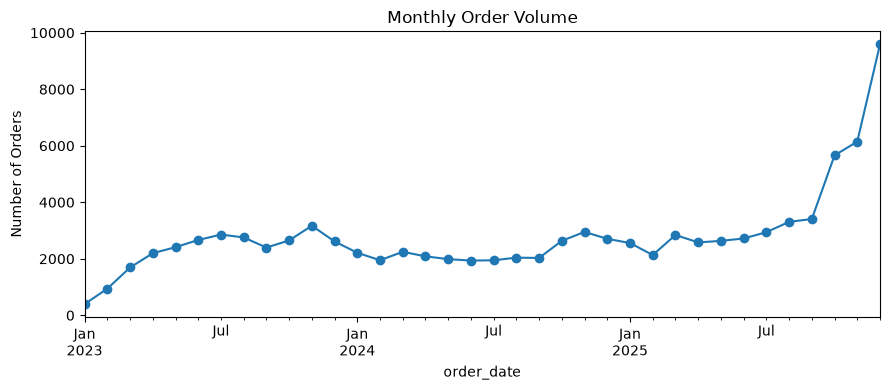

In [6]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

monthly_orders = orders.set_index("order_date").resample("MS")["order_id"].count()

monthly_orders.plot(figsize=(9, 4), marker="o")
plt.title("Monthly Order Volume")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [7]:
display(customers["customer_status"].value_counts())
display(customers[["total_orders", "total_spend"]].describe().round(2))

customer_status
Churned            13365
Active              7234
Never Purchased     2300
At Risk             2101
Name: count, dtype: int64

,total_orders,total_spend
count,25000.00,25000.00
mean,3.88,100031.11
std,3.32,130582.71
min,0.00,0.00
25%,1.00,11598.90
50%,3.00,47466.04
75%,5.00,140534.11
max,24.00,1310772.39


In [8]:
never_ids = customers.loc[
    customers["customer_status"] == "Never Purchased", "customer_id"
]

orders[orders["customer_id"].isin(never_ids)]["order_status"].value_counts()

order_status
Failed    123
Name: count, dtype: int64

In [9]:
display(products["category"].value_counts())
display(products.groupby("category")["price"].agg(["count", "mean"]).round(2))

category
Fashion                   67
Grocery                   54
Home & Kitchen            51
Electronics               47
Mobile Accessories        33
Bags                      30
Footwear                  29
Beauty                    29
Personal Care             27
Health & Wellness         26
Toys                      25
Appliances                21
Books                     21
Furniture                 18
Sports                    17
Stationery                16
Baby Care                  8
Watches                    8
Office Supplies            7
Musical Instruments        6
Pet Supplies               5
Automotive Accessories     5
Name: count, dtype: int64

,count,mean
category,,
Appliances,21,16071.90
Automotive Accessories,5,1622.00
Baby Care,8,1245.00
Bags,30,1862.67
Beauty,29,923.79
Books,21,558.10
Electronics,47,22784.68
Fashion,67,1561.64
Footwear,29,2242.41


In [10]:
print(items.columns.tolist())
display(items.head(3))

['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'discount_percentage', 'item_revenue', 'item_cost', 'profit']


,order_item_id,order_id,product_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit
0,OI10000000,ORD1000000,PROD10347,4,150.0,6.5,561.0,515.92,45.08
1,OI10000001,ORD1000000,PROD10510,1,1150.0,5.0,1092.5,752.18,340.32
2,OI10000002,ORD1000000,PROD10305,2,960.0,8.0,1766.4,1217.66,548.74


In [11]:
sales = (
    items.merge(orders[["order_id", "order_status"]], on="order_id")
    .merge(products[["product_id", "category"]], on="product_id")
)

sales = sales[sales["order_status"] == "Delivered"].copy()
sales["sales_amount"] = sales["quantity"] * sales["unit_price"]

display(sales.groupby("category")["sales_amount"].sum().sort_values(ascending=False).round(2))

category
Electronics               1.141972e+09
Appliances                3.748904e+08
Home & Kitchen            1.465437e+08
Furniture                 1.388869e+08
Fashion                   1.294985e+08
Footwear                  7.616305e+07
Bags                      5.197800e+07
Health & Wellness         2.964539e+07
Sports                    2.429919e+07
Toys                      2.274942e+07
Beauty                    2.152530e+07
Watches                   1.964083e+07
Musical Instruments       1.925356e+07
Books                     1.864843e+07
Grocery                   1.707437e+07
Personal Care             1.339808e+07
Mobile Accessories        1.001882e+07
Stationery                7.477480e+06
Baby Care                 6.374700e+06
Pet Supplies              6.344820e+06
Automotive Accessories    1.585630e+06
Office Supplies           1.439210e+06
Name: sales_amount, dtype: float64

In [12]:
print("Customers:", len(customers))
print("Orders:", len(orders))
print("Products:", len(products))
print("Order items:", len(items))
print("Order date range:", orders["order_date"].min(), "to", orders["order_date"].max())

Customers: 25000
Orders: 100000
Products: 550
Order items: 254331
Order date range: 2023-01-01 00:00:00 to 2025-12-31 00:00:00
